# 43 - Support and rarity: the two mechanisms in a controlled simulation

The paper's two failure mechanisms are claims about any VAE with shared parameters, not about gene
expression. This notebook tests them where the generating process is known. Ten common Gaussian
components in fifty dimensions, one rare component of a hundred points, a Gaussian VAE, and two knobs.

**Support.** The rare component sits 1, 2, 4, or 8 standard deviations from its nearest common
component. At 1 its points lie inside the common data's mass and the retain set keeps their region
alive; at 8 nothing in the retain set resembles them.

**Forget fraction.** All of the rare component's training points, or half of them, which separates
forgetting a group from forgetting individuals of a type the model keeps seeing.

For each of the eight configurations: a baseline, three clean retrains (seed 100 the reference, 101
and 102 the audit floor), retain-only fine-tuning measured every five epochs for 100 epochs, gradient
ascent then fine-tune, a continuous forget objective, and likelihood-targeted fine-tuning with the
retrained model's level (an oracle, known here by construction), the cross-component look-alikes'
level, and the held-out same-component level. Instruments as in notebooks 8, 41, and 42.

In [1]:
import sys
sys.path.insert(0, '../src')
import json, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from mog import (generate_mog_data, stratified_split, forget_indices, select_matched, train_vae, retain_finetune,
                 gradient_ascent_then_finetune, forget_push, targeted_finetune, Instruments, audit_auc, audit_auc_ci, advantage)
from likelihood_audit import neg_elbo_per_cell

plt.style.use('seaborn-v0_8-whitegrid')
torch.set_num_threads(4)
OUTPUT_DIR = Path('../outputs/p9')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
K, D, N, RARE_N, SEED = 10, 50, 20000, 100, 42
DISTANCES, FRACTIONS = [1.0, 2.0, 4.0, 8.0], [1.0, 0.5]
VAE_KW = dict(hidden=(128, 64), latent=8, epochs=200, lr=1e-3, batch_size=256, kl_warmup_epochs=20)
FT_EPOCHS, FT_EVERY = 100, 5
print('configurations:', len(DISTANCES) * len(FRACTIONS))

configurations: 8


In [2]:
def run_configuration(distance, fraction):
    X, labels, meta = generate_mog_data(K=K, d=D, n=N, seed=SEED, rare_n=RARE_N, rare_distance_sd=distance)
    rare = meta['rare_component']
    train_idx, unseen_idx = stratified_split(labels, 0.2, seed=SEED, rare_component=rare, rare_holdout_fraction=0.4)
    f_idx = forget_indices(labels, train_idx, component=rare, fraction=fraction, seed=SEED)
    r_idx = np.setdiff1d(train_idx, f_idx)
    baseline = train_vae(X[train_idx], seed=SEED, **VAE_KW)
    pool = unseen_idx[labels[unseen_idx] != rare]
    cross = pool[select_matched(baseline, X[f_idx], X[pool], k=10)]
    within = unseen_idx[labels[unseen_idx] == rare]
    retrains = {s: train_vae(X[r_idx], seed=s, **VAE_KW) for s in (100, 101, 102)}
    ref = retrains[100]
    ins = Instruments(baseline, ref, X[f_idx], X[cross], X[within], X[r_idx], seed=SEED)
    allr = {100: ref, **retrains}
    pair_ci = {f'{a}->{b}': audit_auc_ci(allr[a], allr[b], X[f_idx], X[cross]) for a in allr for b in allr if a != b}   # every ordered pair of retrained models (reference-independent range)
    band_ci = [pair_ci['100->101'], pair_ci['100->102']]; band = [b['auc'] for b in band_ci]; band_all_pairs = [v['auc'] for v in pair_ci.values()]
    oracle = float(neg_elbo_per_cell(ref, torch.as_tensor(X[f_idx])).mean())
    levels = {'baseline_lookalikes': float(neg_elbo_per_cell(baseline, torch.as_tensor(X[cross])).mean()),
              'retrain_lookalikes': float(neg_elbo_per_cell(ref, torch.as_tensor(X[cross])).mean()),
              'retrain_within': float(neg_elbo_per_cell(ref, torch.as_tensor(X[within])).mean()),
              'baseline_within': float(neg_elbo_per_cell(baseline, torch.as_tensor(X[within])).mean())}
    erosion = [{'epoch': 0, **ins.measure(baseline)}]
    ft_long = retain_finetune(baseline, X[r_idx], epochs=FT_EPOCHS, seed=SEED,
                              callback=lambda e, m: erosion.append({'epoch': e, **ins.measure(m)}) if e % FT_EVERY == 0 else None)
    models = {'baseline': baseline, 'retrain': ref,
              'retain fine-tune, 10 epochs': retain_finetune(baseline, X[r_idx], epochs=10, seed=SEED),
              'retain fine-tune, 100 epochs': ft_long,
              'gradient ascent + fine-tune': gradient_ascent_then_finetune(baseline, X[f_idx], X[r_idx], seed=SEED),
              'forget push (continuous)': forget_push(baseline, X[f_idx], X[r_idx], epochs=20, seed=SEED),
              'targeted, oracle level': targeted_finetune(baseline, X[f_idx], X[r_idx], target=oracle, seed=SEED)[0],
              'targeted, cross look-alikes': targeted_finetune(baseline, X[f_idx], X[r_idx], target=X[cross], seed=SEED)[0],
              'targeted, held-out same component': targeted_finetune(baseline, X[f_idx], X[r_idx], target=X[within], seed=SEED)[0]}
    rows = {name: ins.measure(m, ci=True) for name, m in models.items()}
    for s in (101, 102):
        rows[f'retrain seed {s}'] = ins.measure(retrains[s], ci=True)
    table = pd.DataFrame(rows).T
    table['advantage_cross'] = table.attacker_cross.map(advantage)
    return {'distance_sd': distance, 'fraction': fraction, 'n_forget': len(f_idx), 'n_retain': len(r_idx), 'n_cross': len(cross),
            'n_within': len(within), 'oracle_level': oracle, 'levels': levels, 'audit_band': band, 'audit_band_ci': [b['ci95'] for b in band_ci], 'audit_band_all_pairs': band_all_pairs, 'audit_pairs': {k: v['auc'] for k, v in pair_ci.items()}, 'erosion': erosion, 'table': table}

configs = {}
for distance in DISTANCES:
    for fraction in FRACTIONS:
        t0 = time.time()
        configs[(distance, fraction)] = run_configuration(distance, fraction)
        c = configs[(distance, fraction)]
        print(f'distance {distance:.0f} sd, fraction {fraction}: forget {c["n_forget"]}, cross {c["n_cross"]}, within {c["n_within"]}, '
              f'retrained level {c["oracle_level"]:.2f}, band {[round(b, 3) for b in c["audit_band"]]}, {time.time() - t0:.0f} s', flush=True)

distance 1 sd, fraction 1.0: forget 60, cross 506, within 40, retrained level 74.04, band [0.275, 0.306], 134 s


distance 1 sd, fraction 0.5: forget 30, cross 286, within 40, retrained level 74.46, band [0.64, 0.521], 125 s


distance 2 sd, fraction 1.0: forget 60, cross 506, within 40, retrained level 75.65, band [0.271, 0.31], 112 s


distance 2 sd, fraction 0.5: forget 30, cross 277, within 40, retrained level 76.03, band [0.654, 0.511], 86 s


distance 4 sd, fraction 1.0: forget 60, cross 453, within 40, retrained level 81.90, band [0.36, 0.408], 93 s


distance 4 sd, fraction 0.5: forget 30, cross 255, within 40, retrained level 81.74, band [0.736, 0.516], 89 s


distance 8 sd, fraction 1.0: forget 60, cross 319, within 40, retrained level 106.39, band [0.712, 0.754], 94 s


distance 8 sd, fraction 0.5: forget 30, cross 301, within 40, retrained level 82.35, band [0.582, 0.23], 88 s


## Support decides what the retain fine-tune does

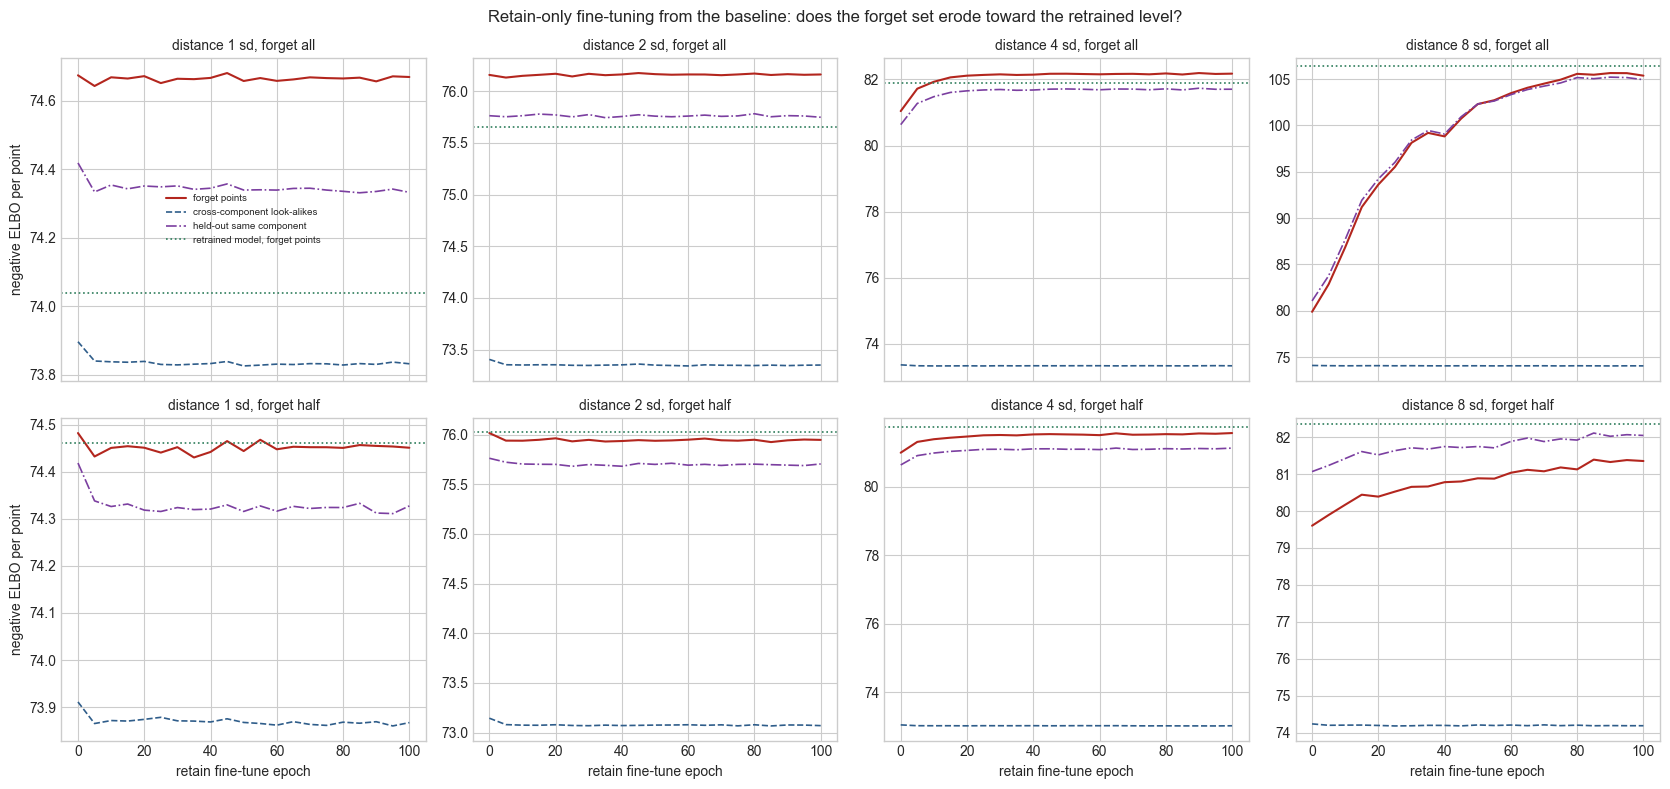

In [3]:
fig, axes = plt.subplots(2, len(DISTANCES), figsize=(4.2 * len(DISTANCES), 8), sharex=True)
for j, distance in enumerate(DISTANCES):
    for i, fraction in enumerate(FRACTIONS):
        c = configs[(distance, fraction)]; e = pd.DataFrame(c['erosion']); ax = axes[i, j]
        ax.plot(e.epoch, e.forget_neg_elbo, color='#B3261E', lw=1.5, label='forget points')
        ax.plot(e.epoch, e.cross_neg_elbo, color='#2F5D8A', lw=1.2, ls='--', label='cross-component look-alikes')
        ax.plot(e.epoch, e.within_neg_elbo, color='#7B3FA0', lw=1.2, ls='-.', label='held-out same component')
        ax.axhline(c['oracle_level'], color='#2E7D5B', lw=1.2, ls=':', label='retrained model, forget points')
        ax.set_title(f'distance {distance:.0f} sd, forget {"all" if fraction == 1.0 else "half"}', fontsize=10)
        if i == 1: ax.set_xlabel('retain fine-tune epoch')
        if j == 0: ax.set_ylabel('negative ELBO per point')
axes[0, 0].legend(fontsize=7)
plt.suptitle('Retain-only fine-tuning from the baseline: does the forget set erode toward the retrained level?', fontsize=12)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'erosion_by_support.png', dpi=150, bbox_inches='tight'); plt.show()

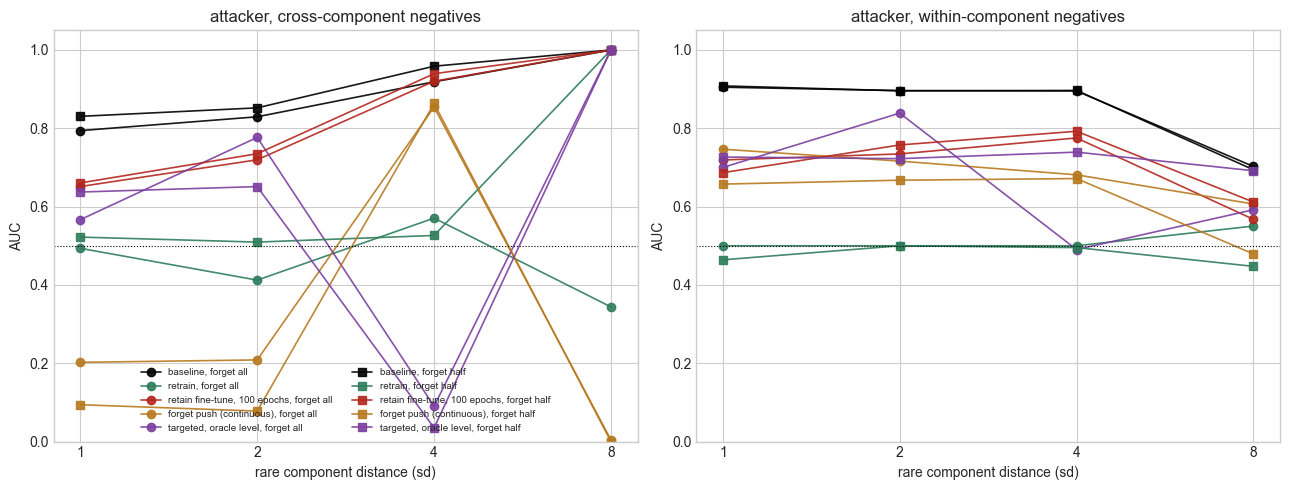

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, key, title in [(axes[0], 'attacker_cross', 'attacker, cross-component negatives'), (axes[1], 'attacker_within', 'attacker, within-component negatives')]:
    for fraction, marker in [(1.0, 'o'), (0.5, 's')]:
        for name, color in [('baseline', 'k'), ('retrain', '#2E7D5B'), ('retain fine-tune, 100 epochs', '#B3261E'), ('forget push (continuous)', '#B7791F'), ('targeted, oracle level', '#7B3FA0')]:
            ys = [configs[(d, fraction)]['table'].loc[name, key] for d in DISTANCES]
            ax.plot(DISTANCES, ys, marker=marker, color=color, lw=1.2, alpha=0.9, label=f'{name}, forget {"all" if fraction == 1.0 else "half"}')
    ax.axhline(0.5, color='k', lw=0.8, ls=':'); ax.set_xscale('log', base=2); ax.set_xticks(DISTANCES); ax.set_xticklabels([f'{d:.0f}' for d in DISTANCES])
    ax.set_xlabel('rare component distance (sd)'); ax.set_ylabel('AUC'); ax.set_title(title); ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'attackers_by_support.png', dpi=150, bbox_inches='tight'); plt.show()

## The calibration axis in every configuration

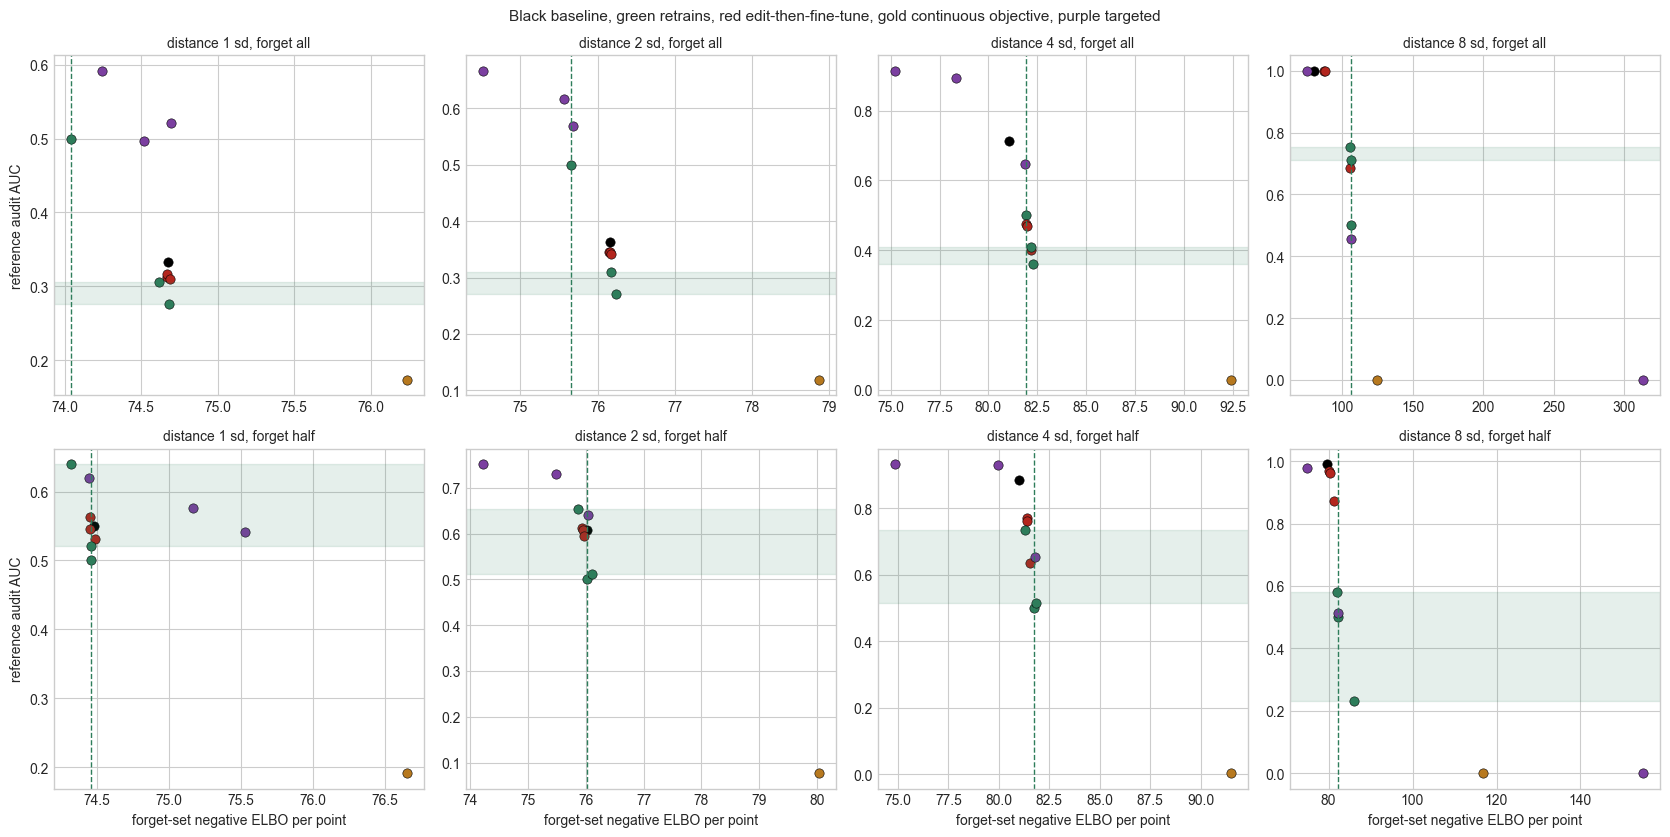

In [5]:
fig, axes = plt.subplots(2, len(DISTANCES), figsize=(4.2 * len(DISTANCES), 8.5))
colors = {'baseline': 'k', 'retrain': '#2E7D5B', 'retrain seed 101': '#2E7D5B', 'retrain seed 102': '#2E7D5B'}
for j, distance in enumerate(DISTANCES):
    for i, fraction in enumerate(FRACTIONS):
        c = configs[(distance, fraction)]; t = c['table']; ax = axes[i, j]
        for label, row in t.iterrows():
            col = colors.get(label, '#7B3FA0' if label.startswith('targeted') else ('#B7791F' if 'push' in label else '#B3261E'))
            ax.scatter(row.forget_neg_elbo, row.audit_cross, s=45, color=col, edgecolor='k', linewidth=0.4)
        ax.axvline(c['oracle_level'], color='#2E7D5B', ls='--', lw=1)
        ax.axhspan(min(c['audit_band']), max(c['audit_band']), color='#2E7D5B', alpha=0.12)
        ax.set_title(f'distance {distance:.0f} sd, forget {"all" if fraction == 1.0 else "half"}', fontsize=10)
        if i == 1: ax.set_xlabel('forget-set negative ELBO per point')
        if j == 0: ax.set_ylabel('reference audit AUC')
plt.suptitle('Black baseline, green retrains, red edit-then-fine-tune, gold continuous objective, purple targeted', fontsize=11)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'calibration_axis_by_support.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
summary_rows = []
for (distance, fraction), c in configs.items():
    for name, row in c['table'].iterrows():
        summary_rows.append({'distance_sd': distance, 'fraction': fraction, 'model': name, **row.to_dict()})
summary = pd.DataFrame(summary_rows)
pd.set_option('display.width', 220)
summary.pivot_table(index=['distance_sd', 'fraction'], columns='model', values='audit_cross').round(3)

model                 baseline  forget push (continuous)  gradient ascent + fine-tune  retain fine-tune, 10 epochs  retain fine-tune, 100 epochs  retrain  retrain seed 101  retrain seed 102  \
distance_sd fraction                                                                                                                                                                            
1.0         0.5          0.551                     0.191                        0.531                        0.546                         0.563      0.5             0.640             0.521   
            1.0          0.333                     0.173                        0.309                        0.313                         0.317      0.5             0.275             0.306   
2.0         0.5          0.609                     0.077                        0.596                        0.613                         0.609      0.5             0.654             0.511   
            1.0          0.364                     0.119                        0.341                        0.345                         0.345      0.5             0.271             0.310   
4.0         0.5          0.884                     0.004                        0.761                        0.772                         0.636      0.5             0.736             0.516   
            1.0          0.713                     0.029                        0.469                        0.476                         0.400      0.5             0.360             0.408   
8.0         0.5          0.991                     0.000                        0.963                        0.969                         0.873      0.5             0.582             0.230   
            1.0          1.000                     0.000                        0.999                        0.999                         0.685      0.5             0.712             0.754   

model                 targeted, cross look-alikes  targeted, held-out same component  targeted, oracle level  
distance_sd fraction                                                                                          
1.0         0.5                             0.576                              0.541                   0.620  
            1.0                             0.521                              0.497                   0.592  
2.0         0.5                             0.752                              0.731                   0.640  
            1.0                             0.666                              0.617                   0.569  
4.0         0.5                             0.934                              0.931                   0.654  
            1.0                             0.914                              0.895                   0.648  
8.0         0.5                             0.978                              0.000                   0.513  
            1.0                             1.000                              0.000                   0.455

In [7]:
summary.pivot_table(index=['distance_sd', 'fraction'], columns='model', values='attacker_cross').round(3)

model                 baseline  forget push (continuous)  gradient ascent + fine-tune  retain fine-tune, 10 epochs  retain fine-tune, 100 epochs  retrain  retrain seed 101  retrain seed 102  \
distance_sd fraction                                                                                                                                                                            
1.0         0.5          0.831                     0.094                        0.750                        0.753                         0.660    0.522             0.646             0.455   
            1.0          0.794                     0.202                        0.736                        0.743                         0.651    0.494             0.499             0.482   
2.0         0.5          0.852                     0.078                        0.807                        0.802                         0.735    0.509             0.563             0.451   
            1.0          0.829                     0.209                        0.780                        0.776                         0.720    0.412             0.500             0.509   
4.0         0.5          0.959                     0.863                        0.947                        0.943                         0.939    0.526             0.713             0.465   
            1.0          0.919                     0.854                        0.922                        0.921                         0.920    0.571             0.549             0.500   
8.0         0.5          1.000                     0.000                        1.000                        1.000                         1.000    1.000             1.000             0.100   
            1.0          1.000                     0.004                        1.000                        1.000                         1.000    0.344             0.430             0.605   

model                 targeted, cross look-alikes  targeted, held-out same component  targeted, oracle level  
distance_sd fraction                                                                                          
1.0         0.5                             0.596                              0.560                   0.637  
            1.0                             0.659                              0.705                   0.567  
2.0         0.5                             0.710                              0.802                   0.651  
            1.0                             0.179                              0.708                   0.777  
4.0         0.5                             0.483                              0.941                   0.035  
            1.0                             0.231                              0.813                   0.090  
8.0         0.5                             1.000                              1.000                   1.000  
            1.0                             0.999                              1.000                   1.000

In [8]:
levels = pd.DataFrame([{'distance_sd': d, 'fraction': f, 'retrained_forget': c['oracle_level'], **c['levels']} for (d, f), c in configs.items()]).set_index(['distance_sd', 'fraction'])
levels.round(2)

retrained_forget  baseline_lookalikes  retrain_lookalikes  retrain_within  baseline_within
distance_sd fraction                                                                                            
1.0         1.0                  74.04                73.90               73.67           73.96            74.42
            0.5                  74.46                73.91               73.81           74.25            74.42
2.0         1.0                  75.65                73.41               73.19           75.51            75.76
            0.5                  76.03                73.14               72.98           75.72            75.76
4.0         1.0                  81.90                73.36               73.25           81.64            80.63
            0.5                  81.74                73.06               73.06           81.19            80.63
8.0         1.0                 106.39                74.11               73.85          105.88            81.07
            0.5                  82.35                74.24               74.22           82.33            81.07

In [9]:
results = {'settings': {'K': K, 'd': D, 'n_common': N, 'rare_n': RARE_N, 'distances_sd': DISTANCES, 'fractions': FRACTIONS, 'vae': VAE_KW,
                        'finetune_epochs': FT_EPOCHS, 'seed': SEED,
                        'estimator': 'likelihood_audit.neg_elbo_per_cell (eval mode, 16 seeded z samples, CPU)',
                        'attacker': 'spectral-norm MLP [256, 256], dropout 0.3, 50 epochs, trained on the baseline, applied to every model'},
           'configurations': [{k: v for k, v in c.items() if k != 'table'} | {'table': c['table'].reset_index().rename(columns={'index': 'model'}).to_dict('records')}
                              for c in configs.values()],
           'levels': levels.reset_index().to_dict('records')}
with open(OUTPUT_DIR / 'synthetic_support.json', 'w') as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(f"saved {OUTPUT_DIR / 'synthetic_support.json'}")

saved ../outputs/p9/synthetic_support.json


## Summary

| Output | Path |
|---|---|
| Results | `outputs/p9/synthetic_support.json` |
| Erosion curves by support | `outputs/p9/erosion_by_support.png` |
| Attackers by support | `outputs/p9/attackers_by_support.png` |
| Calibration axis by configuration | `outputs/p9/calibration_axis_by_support.png` |

**Two membership signals, seen by different instruments.** A group signal exists only when the retain
set cannot stand in for the forget set, that is when the whole rare component is forgotten and it sits
4 or 8 standard deviations from the common data; the retrained models then fit it worse than the
baseline does and the cross-component audit reads 0.71 and 1.0. At 1 and 2 standard deviations, and
whenever half the component stays in the retain set, the retrained models fit the forget points as
well as the baseline does and there is no group signal. A per-point signal exists in every
configuration and lives in the latent features, not in the likelihood: the within-component attacker
reads the baseline at 0.90 (0.70 when the component is isolated) against 0.42 to 0.57 for the
retrained models, while the within-component audit stays near chance. The training points are placed
differently from held-out members of their own component, not fitted better.

**Support sets the timescale on which retain-only fine-tuning erodes the group signal.** Inside the
tail of the common data (4 sd) the retain gradient reclaims the region and the forget points reach the
retrained level within ten epochs. Isolated (8 sd) they drift there over the whole run (87 at epoch 10,
98 at 30, 105 at 100, against 106), because nothing in the retain set acts on that region and the
excess fit is lost only as the shared parameters move for other reasons. The per-point latent signal
decays slowly everywhere (0.90 to between 0.69 and 0.79 after 100 epochs where the component overlaps
the common data, 0.70 to 0.57 where it is isolated) and no post-hoc method removes it; only the
retrained models are at chance.

**The continuous objective over-corrects the likelihood and leaves a latent artifact.** The forget
push drives the audit to 0.00 to 0.19 in every configuration while the cross-component attacker still
separates the forget points, at 0.85 when the component sits at 4 sd and by inverted ranking elsewhere.

**The right likelihood level is not enough, and the observable levels are wrong.** Given the retrained
model's level, the targeted method lands on it (audit 0.46 to 0.65) but the attackers still separate
the forget points (within 0.49 to 0.84; cross inverted to 0.04 to 0.09 at 4 sd), because matching the
likelihood does not reproduce the retrained model's latent geometry. Calibrating to the model's fit of
cross-component look-alikes moves the forget points the wrong way, to a better fit, in every
configuration where a group signal exists. Calibrating to the held-out members of the same component
is a no-op where the per-point likelihood excess is small and runs away where the group is isolated,
since the target moves with the forget points. Nothing a controller can observe supplies the
retrained model's level, and the level alone would not settle the latent signal.

The retrain-versus-retrain audit band is wide here (two retrained seeds differ from the reference by
up to half a nat on sixty points), so the band is reported per configuration rather than assumed to
bracket 0.5.